This week, we use a two-variable conductance-based model. It is a simplified representation of neuronal dynamics, similar in structure to the classic Morris-Lecar model, but using sodium and potassium
currents. It describes the dynamics of the membrane potential ($V$) and a slower, voltage-dependent
potassium channel gating variable ($n$). The system of ODEs is given by:
$$C_m \frac{dV}{dt} = -I_{ion}(V, n) + I_{app}$$
$$\frac{dn}{dt} = \phi(n_\infty (V) - n)$$
where the total ionic current is composed of sodium, potassium, and leak components:
$$I_{ion}(V, n) = g_{Na} m_\infty(V)(V-E_{Na}) + g_K n(V-E_K) + g_l(V-E_l)$$
The voltage-dependent gating functions for sodium activation ($m_\infty$) and potassium activation ($n_\infty$) are
sigmoidal:
$$m_\infty(V) = \frac{1}{1 + \exp \left(\frac{v_1-V}{k_1}\right )}$$
$$n_\infty(V) = \frac{1}{1 + \exp \left(\frac{v_3-V}{k_3}\right )}$$

In [2]:
import PyDSTool as dst
# The tool we will use for Dynamical Systems is PyDSTool https://github.com/robclewley/pydstool
import numpy as np
from matplotlib import pyplot as plt

In [11]:
# 1. Define the system

# Create a PyCont Instance
DSargs = dst.args(name="Excitable_cell_model")

# Define the parameters. These are different from "variables" and their values are determined prior to integration.

pars = {
    'C_m': 1.0, 'g_Na': 20.0, 'g_K': 10.0, 'g_l': 8.0,
    'E_Na': 60.0, 'E_K': -90.0, 'E_l': -80.0, 'v1': -20.0,
    'k1': 15.0, 'v3': -45.0, 'k3': 5.0, 'phi': 2.0,
    'I_app': 0,
    #'I_app': 200,
}
# Define aux functions
fnspecs = {
    "I_ion": (['V', 'n'], "g_Na * m_inf(V) * (V-E_Na) + g_K*n*(V-E_K) + g_l * (V-E_l)"),
    "m_inf": (['V'], "1 / (1 + exp((v1 - V) / k1))"),
    "n_inf": (['V'], "1 / (1 + exp((v3 - V) / k3))"),
}


# Define the ODEs.
varspecs = {
    "V": "1/C_m * -I_ion(V, n) + I_app",
    "n": "phi*(n_inf(V) - n)"
}

# Define the initial conditions. These are the initial conditions for the ODE. In our case, we just have a single ODE such that x(t).
ics = {
    "V": 0,
    "n": 0,
}

# Define a domain for V. It is needed when finding steady states.
domain = {
    "V": [-70, 0],
    "n": [0, 1],
}


DSargs.pars = pars
DSargs.fnspecs = fnspecs
DSargs.varspecs = varspecs
DSargs.ics = ics
DSargs.xdomain = domain

Computing trajectory...


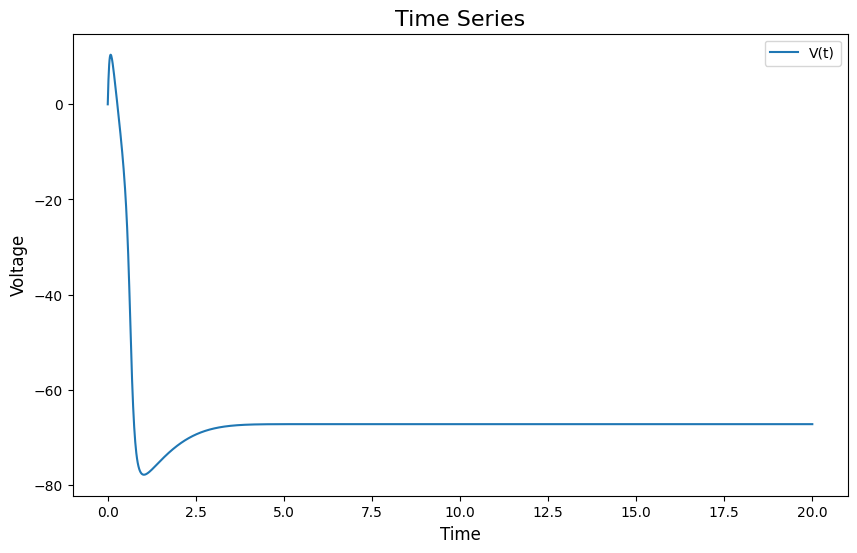

{'V': -67.26763784100643, 'n': 0.011503570465007827}


In [12]:
# This module is used to plot phaseplanes and nullclines
from PyDSTool.Toolbox import phaseplane as pp
# 2. Compute the trajectory

# We choose which integrator to use, in this case it uses scipy' VODE
ode_sys = dst.Generator.Vode_ODEsystem(DSargs)
# Define the range of time.
ode_sys.set(tdata=[0, 20])

print("Computing trajectory...")
trajectory = ode_sys.compute('dimensionless_run')
points = trajectory.sample()

fig_1, ax_1 = plt.subplots(figsize=(10, 6))
ax_1.plot(points['t'], points['V'], label='V(t)')
ax_1.set_title('Time Series', fontsize=16)
ax_1.set_xlabel('Time', fontsize=12)
ax_1.set_ylabel('Voltage', fontsize=12)
plt.legend()
plt.show()

# Now find the steady state and compare it with the analyical solution
fp_coord = pp.find_fixedpoints(ode_sys, n=4, eps=1e-8)[0]
print(fp_coord)

In [13]:
# 3. Start Bifurcation Analysis
#ode_sys = dst.Generator.Vode_ODEsystem(DSargs)

PyCont = dst.ContClass(ode_sys)
PCargs_EQ = dst.args(name='EQ1', type='EP-C')  # Equilibrium curve
PCargs_EQ.freepars = ['I_app'] # Parameter we want to bifurcate against
PCargs_EQ.MaxNumPoints = 400 # Maximum number of points, continuation will stop if exceeds this limit
PCargs_EQ.MaxStepSize = 1 # Defines the maximum step size at each step of continuation, this is an important parameter and it will depend on the system
PCargs_EQ.MinStepSize = 1e-3 # Defines the minimum step size at each step of continuation. Depends on the system
PCargs_EQ.LocBifPoints = 'all' # Specifies the points to look for. LP denotes for limit point aka saddle point.
PCargs_EQ.SaveEigen = True
PCargs_EQ.SaveJacobian = True
PCargs_EQ.verbosity = 2
PCargs_EQ.initpoint = fp_coord
PyCont.newCurve(PCargs_EQ)

# Forward continuation
PyCont['EQ1'].forward()

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  2.631853027447072e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000001

H Point found 
0 : 
V  =  -52.24526440083307
n  =  0.1901473714756651
I_app  =  59.54757111081302

Eigenvalues = 

     (0.000000,4.388122)
     (0.000000,-4.388122)


w = 4.388121522925993
l1 = -0.012610533465436202

Checking...
  |q| = 1.000000
  |<p,q> - 1| =  4.019147396079118e-17
  |Aq - iwq| = 0.000000
  |A*p + iwp| = 0.000005

H Point found 
0 : 
V  =  -26.870679040070016
n  =  0.9740644837144071
I_app  =  366.794590990449

Eigenvalues = 

     (0.000000,1.542501)
     (0.000000,-1.542501)


w = 1.5425011867603002
l1 = -0.03239504076842641



Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (Ip, V) space')

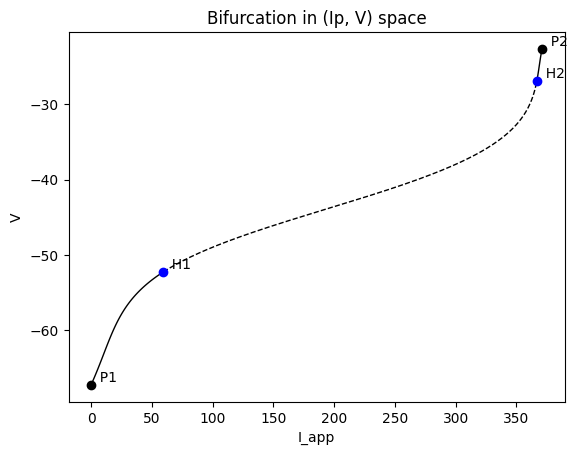

In [16]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
PyCont.display(('I_app', 'V'), stability=True)
plt.title("Bifurcation in (Ip, V) space")

In [17]:
# Now we want to compute the LCCs

PCargs_LC = dst.args(name='LC1', type='LC-C')  # LCC curve
PCargs_LC.freepars = ['I_app'] # Parameter we want to bifurcate against
PCargs_LC.MaxNumPoints = 400 # Maximum number of points, continuation will stop if exceeds this limit
PCargs_LC.MaxStepSize = 1 # Defines the maximum step size at each step of continuation, this is an important parameter and it will depend on the system
PCargs_LC.MinStepSize = 1e-3 # Defines the minimum step size at each step of continuation. Depends on the system
PCargs_LC.LocBifPoints = 'all' # Specifies the points to look for. LP denotes for limit point aka saddle point.
PCargs_LC.SaveEigen = True
PCargs_LC.SaveJacobian = True
PCargs_LC.verbosity = 2
PCargs_LC.initpoint = 'EQ1:H1'
PyCont.newCurve(PCargs_LC)

# Forward continuation
PyCont['LC1'].forward()

running build
running config_cc
unifing config_cc, config, build_clib, build_ext, build commands --compiler options
running config_fc
unifing config_fc, config, build_clib, build_ext, build commands --fcompiler options
running build_src
build_src
building extension "_auto_Excitable_cell_model_vf" sources
swig: /notebooks/auto_temp/auto_Excitable_cell_model_vf.i
swig -python -I/usr/local/lib/python3.9/site-packages/numpy/core/include -I/notebooks -I/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/module/include -I/notebooks/auto_temp -I/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/include -o auto_temp/src.linux-aarch64-3.9/auto_temp/auto_Excitable_cell_model_vf_wrap.c -outdir auto_temp/src.linux-aarch64-3.9/auto_temp /notebooks/auto_temp/auto_Excitable_cell_model_vf.i
build_src: building npy-pkg config files
running build_ext
new_compiler returns <class 'distutils.unixccompiler.UnixCCompiler'>
customize UnixCCompiler
customize UnixCCompiler using build_ext
*

/usr/local/lib/python3.9/site-packages/setuptools/command/install.py:34: SetuptoolsDeprecationWarning: setup.py install is deprecated. Use build and pip and other standards-based tools.
  warnings.warn(


gcc -shared auto_temp/auto_temp/src.linux-aarch64-3.9/auto_temp/auto_Excitable_cell_model_vf_wrap.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/auto.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/autlib1.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/autlib2.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/autlib3.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/autlib4.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/autlib5.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/eispack.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/conpar.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/setubv.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/reduce.o auto_temp/usr/local/lib/python3.9/site-packages/PyDSTool/PyCont/auto/src/dma

Plotting diagram.


Text(0.5, 1.0, 'Bifurcation in (I_app, V) space')

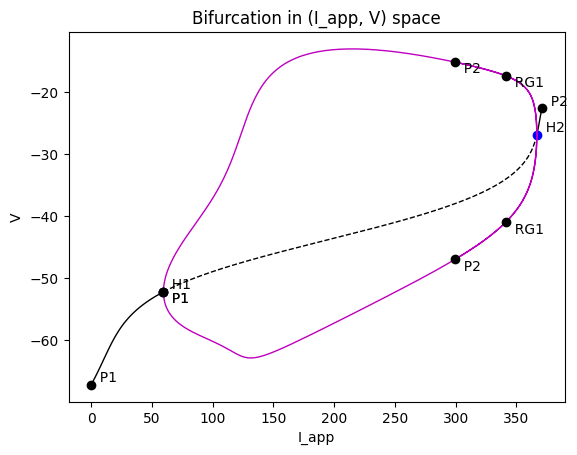

In [18]:
# 4. Plot the Results
print("Plotting diagram.")

plt.figure(figsize=(10, 6))
PyCont.display(('I_app', 'V'), stability=True)
PyCont['LC1'].display(('I_app','V_min'), stability=True)
plt.title("Bifurcation in (I_app, V) space")

In [19]:
PyCont["LC1"].sol

Pointset LC1 (non-parameterized)
Coordinates:
I_app:  [59.54757111 59.54763669, ..., 300.57065936 299.5734466 ]
V_max:  [-52.2452644 -52.2311185, ..., -15.19129751 -15.14891966]
V_min:  [-52.2452644  -52.25940047, ..., -46.86643553 -46.98570766]
_T:  [1.43186219 1.43186179, ..., 1.65808304 1.65256898]
n_max:  [0.19014737 0.19032827, ..., 0.9475418  0.94680827]
n_min:  [0.19014737 0.18996705, ..., 0.69636682 0.69336705]
Labels by index:  0: {P: {keys=name}}, {LC: {keys=data,stab}},
                  1: {LC: {keys=data,stab}},
                  2: {LC: {keys=data,stab}},
                  .
                  .
                  .
                  397: {LC: {keys=data,stab}},
                  398: {LC: {keys=data,stab}},
                  399: {P: {keys=cycle,data,name}}, {LC: {keys=data,stab}}

In [20]:
import logging
# To get rid of messy logs
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

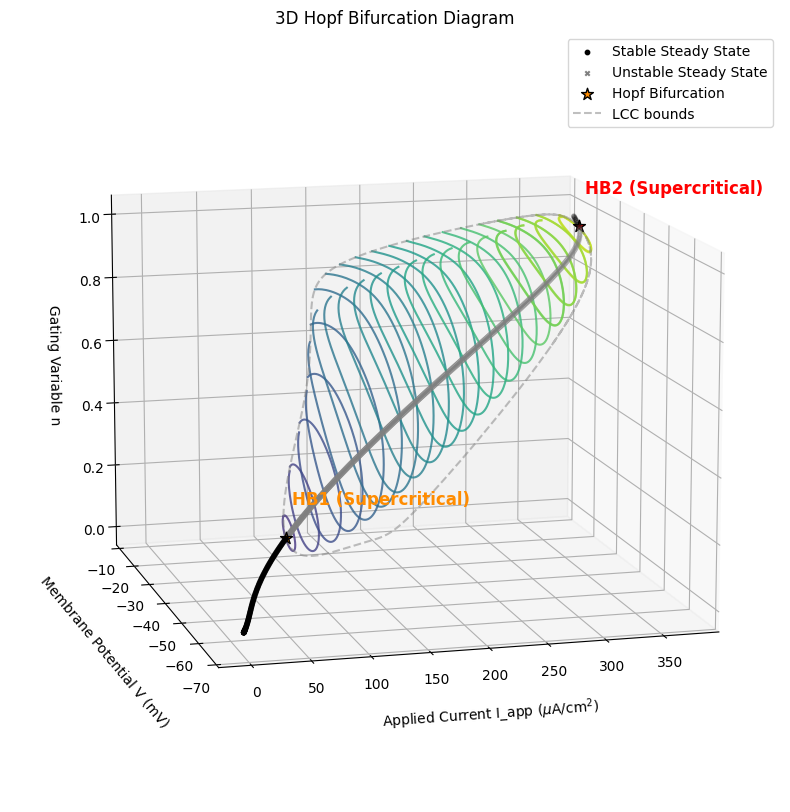

In [21]:
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection='3d')

# Get SS data
eq_sol = PyCont['EQ1'].sol
i_app_eq = eq_sol['I_app']
v_eq = eq_sol['V']
n_eq = eq_sol['n']


# First Hopf Point
h1 = PyCont['EQ1'].getSpecialPoint('H1')
h1_I, h1_V, h1_n = h1['I_app'], h1['V'], h1['n']
l1_h1 = h1.labels['H']['data'].l1
type_h1 = "Supercritical" if l1_h1 < 0 else "Subcritical"

# Second Hopf Point
h2 = PyCont['EQ1'].getSpecialPoint('H2')
h2_I, h2_V, h2_n = h2['I_app'], h2['V'], h2['n']
l1_h2 = h2.labels['H']['data'].l1
type_h2 = "Supercritical" if l1_h2 < 0 else "Subcritical"

# System is unstable betwen H1 and H2
min_H, max_H = min(h1_I, h2_I), max(h1_I, h2_I)
stable_mask = (i_app_eq <= min_H) | (i_app_eq >= max_H)
unstable_mask = (i_app_eq > min_H) & (i_app_eq < max_H)

ax.scatter(i_app_eq[stable_mask], v_eq[stable_mask], n_eq[stable_mask], 
           c='k', s=10, label='Stable Steady State')
ax.scatter(i_app_eq[unstable_mask], v_eq[unstable_mask], n_eq[unstable_mask], 
           c='gray', s=10, marker='x', label='Unstable Steady State')

# Plot HB1
ax.scatter(h1_I, h1_V, h1_n, c='darkorange', s=80, marker='*', edgecolor='k', zorder=10, label='Hopf Bifurcation')
ax.text(h1_I + 5, h1_V, h1_n + 0.1, f'HB1 ({type_h1})', color='darkorange', fontsize=12, weight='bold', zorder=10)

# Plot HB2
ax.scatter(h2_I, h2_V, h2_n, c='red', s=80, marker='*', edgecolor='k', zorder=10)
ax.text(h2_I + 5, h2_V, h2_n + 0.1, f'HB2 ({type_h2})', color='red', fontsize=12, weight='bold', zorder=10)

# Extract LCC data
lc_sol = PyCont['LC1'].sol
lc_I = lc_sol['I_app']
lc_Vmax = lc_sol['V_max']
lc_Vmin = lc_sol['V_min']
lc_nmax = lc_sol['n_max']
lc_nmin = lc_sol['n_min']
lc_T = lc_sol["_T"]


step = max(1, len(lc_I) // 25)
for idx in range(0, len(lc_I), step):
    i_val = lc_I[idx]
    
    ode_sys.set(pars={'I_app': i_val})
    ode_sys.set(ics={'V': lc_Vmax[idx], 'n': lc_nmax[idx]})
    
    ode_sys.set(tdata=[0, lc_T[idx]])
    pts = ode_sys.compute('traj').sample()
    
    ax.plot(np.full_like(pts['V'], i_val), pts['V'], pts['n'], 
            lw=1.5, color=plt.cm.viridis(i_val / 400.0), alpha=0.8)

# Plot the LCC bounds
ax.plot(lc_I, lc_Vmax, lc_nmax, color='gray', linestyle='--', alpha=0.5, label='LCC bounds')
ax.plot(lc_I, lc_Vmin, lc_nmin, color='gray', linestyle='--', alpha=0.5)

ax.set_xlabel(r'Applied Current I_app ($\mu$A/cm$^2$)', labelpad=15)
ax.set_ylabel('Membrane Potential V (mV)', labelpad=15)
ax.set_zlabel('Gating Variable n', labelpad=10)
ax.set_title('3D Hopf Bifurcation Diagram')
ax.view_init(elev=12, azim=-105)
ax.legend()

plt.show()